In [38]:
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error
)
from sklearn.model_selection import train_test_split

In [32]:
df = sns.load_dataset('anscombe')

In [22]:
df.head()

,dataset,x,y
0,I,10.0,8.04
1,I,8.0,6.95
2,I,13.0,7.58
3,I,9.0,8.81
4,I,11.0,8.33


In [23]:
print(df.shape)

(44, 3)


In [29]:
for name, g, in df.groupby('dataset'):
  X = g[["x"]]
  y = g["y"]
  m = LinearRegression().fit(X, y)
  print(f"name -> {name}    w = {round(m.coef_[0], 2)}    R^2 = {round(m.score(X, y), 3)}")

name -> I    w = 0.5    R^2 = 0.667
name -> II    w = 0.5    R^2 = 0.666
name -> III    w = 0.5    R^2 = 0.666
name -> IV    w = 0.5    R^2 = 0.667


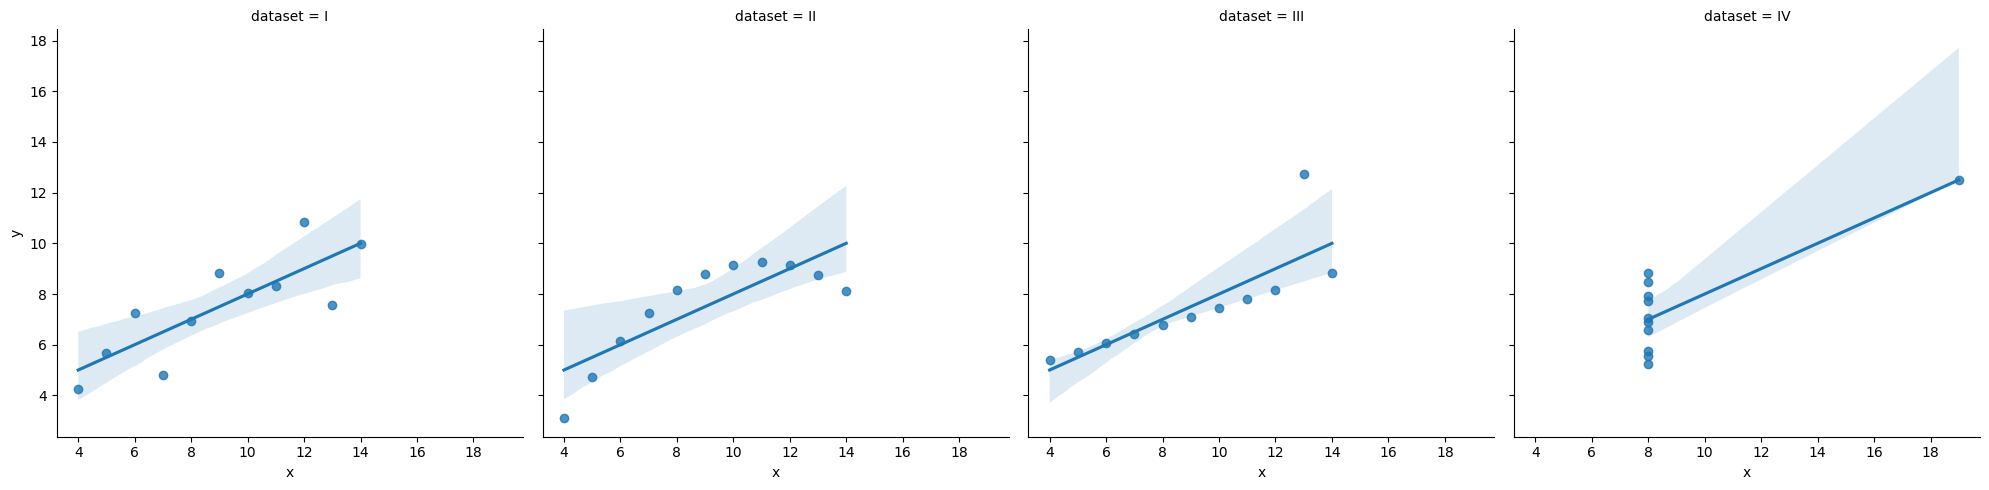

In [31]:
sns.lmplot(data=df, x='x', y='y', col='dataset', col_wrap=4)
plt.show()

In [34]:
df_hprice = pd.read_csv('/content/train.csv')

In [36]:
df_hprice.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [41]:
X = df_hprice[['GrLivArea', "OverallQual"]]
y = df_hprice['SalePrice']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_true = y_test

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = root_mean_squared_error(y_true, y_pred)
med_ae = median_absolute_error(y_true, y_pred)
mape = mean_absolute_percentage_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print(f"Mean Absolute Error (MAE):         {mae:.4f}")
print(f"Mean Squared Error (MSE):          {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):    {rmse:.4f}") # Added print for RMSE
print(f"Median Absolute Error (Median AE): {med_ae:.4f}")
print(f"Mean Absolute Pct Error (MAPE):    {mape:.4f} (or {mape*100:.2f}%)")
print(f"R² Score:                          {r2:.4f}")

Mean Absolute Error (MAE):         28555.2500
Mean Squared Error (MSE):          1950070708.6602
Root Mean Squared Error (RMSE):    44159.6049
Median Absolute Error (Median AE): 19756.5527
Mean Absolute Pct Error (MAPE):    0.1757 (or 17.57%)
R² Score:                          0.7458


In [43]:
def adjusted_r2(r2, y_true, y_pred, n_features):

    n_samples = len(y_true)

    adj_r2 = 1 - ((1 - r2) * (n_samples - 1) / (n_samples - n_features - 1))

    return adj_r2

print(f"Adjusted R² Score: {adjusted_r2(r2, y_true, y_pred, 2)}")

Adjusted R² Score: 0.7440048891477131
